# 01 · Construcción del corpus

Corpus de noticias de política española con dos fuentes: 5000 noticias del corpus *Spanish Political Fake News* (Universidad de Vigo, Kaggle) y 150 obtenidas por web scraping con BeautifulSoup (bulos verificados por Maldita y Newtral, y noticias de elDiario.es). Cada noticia se guarda como `.txt` en `corpus/Verdad/` o `corpus/Falso/`.

## 0. Configuración

In [1]:
import html
import json
import random
import re
import time
from pathlib import Path

import pandas as pd
import requests
from bs4 import BeautifulSoup

SEMILLA = 42
BASE = Path.cwd()
DATOS = BASE / "datos"
CORPUS = BASE / "corpus"
VIGO_CSV = DATOS / "D57000_complete.csv"

N_CURADO_POR_CLASE = 2500   # 2500 + 2500 = 5000 (mínimo de la Fuente 2)
N_SCRAPING_POR_CLASE = 75   # 75 + 75 = 150 = 50 por integrante (Fuente 1)
EXTRA = 10                  # noticias de más, por si en la revisión manual descartamos alguna

random.seed(SEMILLA)
pd.set_option("display.max_colwidth", 160)

## 1. Fuente 2: corpus curado

*Spanish Political Fake News* (Otero Vizoso, 2023), Kaggle, licencia CC BY 4.0. Archivo `datos/D57000_complete.csv`, separado por `;`, con `Label` = 1 (verdadera) o 0 (falsa).

In [2]:
vigo = pd.read_csv(VIGO_CSV, sep=";", encoding="utf-8")
print(vigo.shape)
vigo.head()

(57231, 5)


,ID,Label,Titulo,Descripcion,Fecha
0,ID,1,Moreno intenta apaciguar el flanco sanitario mientras enreda con la fecha de las elecciones,El presidente abre la puerta a unos comicios en junio que no sean en domingo.,19/04/2022
1,ID,1,La Abogacía del Estado se retira como acusación en la pieza de Iberdrola del 'caso Tándem',"En un escrito, la abogada del Estado Rosa María Seoane argumenta su decisión en la falta de legitimación activa respecto de los delitos imputados.",17/09/2021
2,ID,0,"Las promesas incumplidas de Pablo Echenique en sanidad, educación y vivienda","Este lunes y martes la Asamblea de Madrid acogerá el debate del estado de la región. El último se celebró hace dos años, el 14 de septiembre de 2020.",12/09/2022
3,ID,1,Sánchez defiende 'resolver el problema' de la ley del 'solo sí es sí' desde el diálogo,"Resulta evidente que la ley ha tenido algunos efectos indeseados. Y me quedo corto, ha destacado el presidente del Gobierno ante sus diputados y senadores.",07/02/2023
4,ID,1,Ian Gibson cierra la lista electoral de la confluencia de Podemos en Granada,"El hispanista, que ya ocupó un puesto simbólico en la lista de la confluencia en las anteriores elecciones municipales de 2019, ha recalcado que su presenci...",12/04/2023


Se unen título y descripción y se eliminan los duplicados.

In [3]:
vigo["texto"] = vigo["Titulo"].str.strip() + ". " + vigo["Descripcion"].str.strip()
antes = len(vigo)
vigo = vigo.dropna(subset=["texto"]).drop_duplicates(subset="texto")
print(f"Duplicados eliminados: {antes - len(vigo)}")
vigo["Label"].value_counts().rename({1: "Verdad", 0: "Falso"})

Duplicados eliminados: 467


Label
Verdad    32913
Falso     23851
Name: count, dtype: int64

Muestra aleatoria balanceada de 2500 noticias por clase.

In [4]:
muestra_curado = (
    vigo.groupby("Label", group_keys=False)
        .sample(n=N_CURADO_POR_CLASE, random_state=SEMILLA)
        .reset_index(drop=True)
)
muestra_curado["clase"] = muestra_curado["Label"].map({1: "Verdad", 0: "Falso"})
muestra_curado["fuente"] = "curado"
muestra_curado["url"] = ""
muestra_curado["clase"].value_counts()

clase
Falso     2500
Verdad    2500
Name: count, dtype: int64

## 2. Fuente 1: web scraping

Funciones de apoyo. Las listas de artículos se leen de los *sitemaps* de cada sitio, porque su paginación usa JavaScript, y el contenido de cada noticia se toma de sus datos estructurados (JSON-LD).

In [5]:
HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/128.0 Safari/537.36"}
PAUSA = 2                 # segundos entre peticiones
DESDE = "20240101"        # solo noticias de 2024 en adelante (Vigo llega hasta junio de 2023)
CALIFICACIONES_FALSAS = {"falso", "falsa", "bulo"}
PALABRAS_POLITICA = [
    "psoe", "pp ", "partido popular", "vox", "sumar", "podemos", "junts", "erc", "bildu", "pnv",
    "partido", "gobierno", "congreso", "senado", "parlamento", "ministr", "presidente", "alcalde",
    "diputad", "eurodiputad", "consejer", "generalitat", "junta de", "moncloa", "elecciones", "votar",
    "voto", "izquierda", "derecha", "ultraderecha", "comunista", "polític", "ley ",
    "sánchez", "sanchez", "feijóo", "feijoo", "abascal", "ayuso", "yolanda díaz", "puigdemont",
    "zapatero", "rajoy", "aznar", "iglesias", "montero", "illa", "mazón", "mazon", "almeida",
    "begoña", "koldo", "ábalos", "trump", "maduro", "meloni", "milei", "petro", "putin",
]


def pedir(url):
    respuesta = requests.get(url, headers=HEADERS, timeout=30)
    respuesta.raise_for_status()
    time.sleep(PAUSA)
    return respuesta.text


def urls_de_sitemap(url):
    sopa = BeautifulSoup(pedir(url), "xml")
    # Solo el <loc> directo de cada <url>/<sitemap>; así se ignoran los <image:loc> de las fotos
    return [entrada.find("loc", recursive=False).get_text(strip=True)
            for entrada in sopa.find_all(["url", "sitemap"])
            if entrada.find("loc", recursive=False)]


def fecha_en_url(url):
    coincidencia = re.search(r"/(\d{8})/", url + "/")
    return coincidencia.group(1) if coincidencia else ""


def json_ld(sopa):
    objetos = []
    for script in sopa.find_all("script", type="application/ld+json"):
        try:
            datos = json.loads(script.string or "")
        except json.JSONDecodeError:
            continue
        if isinstance(datos, dict):
            datos = datos.get("@graph", [datos])
        objetos.extend(d for d in datos if isinstance(d, dict))
    return objetos


def es_politica(texto):
    texto = texto.lower()
    return any(palabra in texto for palabra in PALABRAS_POLITICA)

Verificación de que `robots.txt` permite descargar las páginas.

In [6]:
from urllib.robotparser import RobotFileParser

PAGINAS_A_USAR = {
    "Maldita (bulos)": "https://maldita.es/malditobulo/20240101/ejemplo/",
    "Newtral (bulos)": "https://www.newtral.es/ejemplo/20240101/",
    "elDiario.es (verdaderas)": "https://www.eldiario.es/politica/ejemplo_1_1.html",
}

filas_robots = []
for sitio, url in PAGINAS_A_USAR.items():
    dominio = "/".join(url.split("/")[:3])
    robots = RobotFileParser()
    robots.parse(requests.get(f"{dominio}/robots.txt", headers=HEADERS, timeout=30).text.splitlines())
    filas_robots.append({"sitio": sitio, "robots.txt": f"{dominio}/robots.txt",
                         "permitido": robots.can_fetch("*", url), "pausa pedida (s)": robots.crawl_delay("*")})
pd.DataFrame(filas_robots)

,sitio,robots.txt,permitido,pausa pedida (s)
0,Maldita (bulos),https://maldita.es/robots.txt,True,NaN
1,Newtral (bulos),https://www.newtral.es/robots.txt,True,2.0
2,elDiario.es (verdaderas),https://www.eldiario.es/robots.txt,True,NaN


Extracción del texto: de los verificadores se guarda la afirmación falsa (`claimReviewed`), no el desmentido; de elDiario.es, título y entradilla.

In [7]:
def extraer_bulo(url):
    sopa = BeautifulSoup(pedir(url), "html.parser")
    for objeto in json_ld(sopa):
        if objeto.get("@type") == "ClaimReview":
            calificacion = (objeto.get("reviewRating") or {}).get("alternateName", "")
            etiquetas = " ".join(a.get_text(" ", strip=True)
                                 for a in sopa.select("a[rel=tag], a[href*='/tag/'], a[href*='/etiqueta/']"))
            titular = sopa.h1.get_text(" ", strip=True) if sopa.h1 else ""
            return {
                "url": url,
                "texto": html.unescape(objeto.get("claimReviewed") or "").strip(),
                "calificacion": calificacion,
                "contexto": f"{titular} {etiquetas}",
            }
    return None


def extraer_verdadera(url):
    sopa = BeautifulSoup(pedir(url), "html.parser")
    for objeto in json_ld(sopa):
        if objeto.get("@type") in ("NewsArticle", "Article", "ReportageNewsArticle"):
            titulo = html.unescape(objeto.get("headline") or "").strip()
            entradilla = html.unescape(objeto.get("description") or "").strip()
            if titulo and entradilla:
                return {"url": url, "texto": f"{titulo}. {entradilla}"}
    return None


def bulo_politico(item):
    return (item["calificacion"].lower() in CALIFICACIONES_FALSAS
            and len(item["texto"].split()) >= 5
            and es_politica(item["texto"] + " " + item["contexto"]))

Recolección en orden aleatorio. Lo descargado se guarda en `datos/scraping_<fuente>.csv` para no repetir el scraping.

In [8]:
def recolectar(urls, extraer, cuantas, fuente, filtro=lambda item: True):
    urls = list(urls)
    random.Random(SEMILLA).shuffle(urls)
    resultados = []
    for url in urls:
        if len(resultados) >= cuantas:
            break
        try:
            item = extraer(url)
        except requests.RequestException as error:
            print("  error:", url, error)
            continue
        if item and filtro(item):
            item["fuente"] = fuente
            resultados.append(item)
            print(f"  {len(resultados)}/{cuantas}  {item['texto'][:90]}")
    return pd.DataFrame(resultados)


def con_cache(fuente, funcion):
    archivo = DATOS / f"scraping_{fuente}.csv"
    if archivo.exists():
        print(f"Usando {archivo.name} ya guardado (bórralo para volver a scrapear)")
        return pd.read_csv(archivo, keep_default_na=False)
    df = funcion()
    df.to_csv(archivo, index=False, encoding="utf-8")
    return df

### 2.1 Falsas: Maldita y Newtral

Bulos de 2024 en adelante, calificados como falsos y de tema político.

In [9]:
N_FALSAS = N_SCRAPING_POR_CLASE + EXTRA
N_MALDITA = N_FALSAS // 2
N_NEWTRAL = N_FALSAS - N_MALDITA


def scrapear_maldita():
    urls = [u for u in urls_de_sitemap("https://maldita.es/sitemap.desinfo.xml")
            if "/malditobulo/" in u and fecha_en_url(u) >= DESDE]
    print(f"Maldita: {len(urls)} bulos desde 2024")
    return recolectar(urls, extraer_bulo, N_MALDITA, "maldita", bulo_politico)


maldita = con_cache("maldita", scrapear_maldita)

Maldita: 2746 bulos desde 2024
  1/42  Vídeo de Nicolás Maduro caminando en el patio de una prisión de Nueva York
  2/42  Un vídeo muestra cómo Giorgia Meloni se tira un pedo y sale corriendo de una conferencia
  3/42  Donald Trump da una ayuda de 1.300 dólares para ayudar a las víctimas del huracán Milton
  4/42  Un magrebí intenta escalar la fachada de un hospital de Tenerife y los bomberos le interce
  5/42  Jóvenes Izquierda Unida: “Hoy levantaramos la bandera republicana y marroqui para celebrar
  6/42  Kamala Harris está borracha en este vídeo grabado en Filipinas en 2022
  7/42  El Gobierno anuncia que Hacienda va a investigar a los jueces del Supremo que han condenad
  8/42  NO AUTORIZO: La nueva regla de Meta permite usar tus fotos. Whatsapp cobrará 0,01 por mens
  9/42  Joe Biden se queda dormido durante una entrevista en directo
  10/42  Orban y Meloni acusan a Pedro Sánchez de malversar millones de euros de la Unión Europea p
  11/42  Alberto Núñez Feijóo, líder del PP, apa

In [10]:
def scrapear_newtral():
    sitemaps = [s for s in urls_de_sitemap("https://newtral.es/sitemap.xml") if "fake-sitemap" in s]
    urls = [u for s in sitemaps for u in urls_de_sitemap(s) if fecha_en_url(u) >= DESDE]
    print(f"Newtral: {len(urls)} bulos desde 2024")
    return recolectar(urls, extraer_bulo, N_NEWTRAL, "newtral", bulo_politico)


newtral = con_cache("newtral", scrapear_newtral)

Newtral: 2150 bulos desde 2024
  1/43  Pablo Iglesias ofrece paquetes de inversión de 1.000 euros para su taberna Garibaldi como 
  2/43  RoRo ha publicado un post con este mensaje: "Os quiero a todo gritando ‘Pedro Sánchez hijo
  3/43  En estas declaraciones Donald Trump se burla de María Corina Machado y asegura que le dijo
  4/43  La agencia de noticias Al Jazeera compartió imágenes de cámaras de seguridad de la muerte 
  5/43  Esta imagen muestra un mercadillo de Navidad en Alemania rodeado de verjas y vehículos pol
  6/43  La FIFA anunció que se repetirá el partido del 30 de junio entre México y Ecuador el viern
  7/43  Este vídeo muestra al presidente de Venezuela, Nicolás Maduro, llegando a México en la vís
  8/43  El ministro de defensa israelí muere en un atentado con un coche bomba.
  9/43  Estados Unidos niega la visa a Lamine Yamal. La estrella del fútbol español podría no esta
  10/43  Emmanuel Macron afirmó que Donald Trump bloqueó su paso por las calles de Nueva York por

### 2.2 Verdaderas: elDiario.es

Artículos de la sección de política nacional desde 2024.

In [11]:
def scrapear_eldiario():
    indice = urls_de_sitemap("https://www.eldiario.es/sitemap_index_25b87.xml")
    meses = [s for s in indice if re.search(r"sitemap_contents_20(2[4-9])_", s)]
    urls = [u for s in meses for u in urls_de_sitemap(s)
            if u.startswith("https://www.eldiario.es/politica/") and "_1_" in u]
    print(f"elDiario: {len(urls)} artículos de política desde 2024")
    return recolectar(urls, extraer_verdadera, N_SCRAPING_POR_CLASE + EXTRA, "eldiario")


eldiario = con_cache("eldiario", scrapear_eldiario)

elDiario: 6758 artículos de política desde 2024
  1/85  El expresidente Gallardón declara como testigo por la compra de una empresa colombiana de 
  2/85  El Supremo confirma las condenas de los militares que usaron el buque Elcano para traficar
  3/85  Felipe González pide a los españoles ante el rey "preservar a toda costa la paz civil". El
  4/85  De Vox a Manos Limpias: una década de querellas como arma política de la extrema derecha. 
  5/85  Maíllo, sobre el futuro de IU: "Los partidos tenemos que canalizar las aspiraciones social
  6/85  La pareja de Ayuso ofreció un pacto a la Fiscalía para declararse culpable de los delitos 
  7/85  Sánchez carga contra el discurso de Feijóo sobre las bajas laborales: "Todo lo que plantea
  8/85  Manuela Carmena, sobre Errejón: "Me parece horrible, nunca pude pensar ni oí nada relativo
  9/85  El Poder Judicial se da cinco días para escoger presidente entre jueces del procés, los ER
  10/85  El Supremo confirma el nombramiento de García Ortiz 

### 2.3 Revisión manual

Se descartan las noticias que no son de política (se descargaron 10 de más por clase) y se toman 75 por clase.

In [12]:
falsas = pd.concat([maldita, newtral], ignore_index=True).drop_duplicates(subset="texto").reset_index(drop=True)
verdaderas = eldiario.drop_duplicates(subset="texto").reset_index(drop=True)
falsas[["fuente", "texto"]]

,fuente,texto
0,maldita,Vídeo de Nicolás Maduro caminando en el patio de una prisión de Nueva York
1,maldita,Un vídeo muestra cómo Giorgia Meloni se tira un pedo y sale corriendo de una conferencia
2,maldita,Donald Trump da una ayuda de 1.300 dólares para ayudar a las víctimas del huracán Milton
3,maldita,Un magrebí intenta escalar la fachada de un hospital de Tenerife y los bomberos le interceptan
4,maldita,Jóvenes Izquierda Unida: “Hoy levantaramos la bandera republicana y marroqui para celebrar la victoria de nuestra selección. Felicidades a todos los que cel...
...,...,...
80,newtral,Esta imagen de un paraje natural ardiendo muestra el incendio de Las Médulas en León.
81,newtral,"El Gobierno de Italia comienza a trasladar inmigrantes a la puerta de la Ciudad del Vaticano después de que el papa Francisco dijera que es un ""pecado recha..."
82,newtral,Donald Trump ha enmarcado el ‘whitepaper’ de bitcoin en la Casa Blanca como muestra este vídeo.
83,newtral,El Gobierno ha anunciado que serán investigados por Hacienda los magistrados del Supremo que han condenado al fiscal general del Estado.


In [13]:
verdaderas[["fuente", "texto"]]

,fuente,texto
0,eldiario,El expresidente Gallardón declara como testigo por la compra de una empresa colombiana de aguas hace 25 años. La fiscal pide cárcel por malversación para to...
1,eldiario,El Supremo confirma las condenas de los militares que usaron el buque Elcano para traficar con droga. La Sala de lo Militar rechaza los recursos de varios a...
2,eldiario,"Felipe González pide a los españoles ante el rey ""preservar a toda costa la paz civil"". El expresidente del Gobierno recibe en el 50 aniversario de la resta..."
3,eldiario,De Vox a Manos Limpias: una década de querellas como arma política de la extrema derecha. El partido de Santiago Abascal y organizaciones como el pseudosind...
4,eldiario,"Maíllo, sobre el futuro de IU: ""Los partidos tenemos que canalizar las aspiraciones sociales, no al contrario"". El nuevo coordinador general de Izquierda Un..."
...,...,...
80,eldiario,El juez del caso Leire Díez abre una pieza separada para buscar pagos del PSOE hacia la exmilitante. Pedraz autoriza a la UCO recabar información de 80 cuen...
81,eldiario,"Villarejo atribuye ahora la operación Kitchen a la posible relación del rey emérito con el tráfico de armas. El comisario habla de una operación ""legal"", ex..."
82,eldiario,"Las coartadas de la cloaca del PP afloran en el juicio a Kitchen: ""Asuntos Internos no vigilaba a Rosalía, la protegía"". El inspector jefe jubilado Jesús Vi..."
83,eldiario,La pareja de Ayuso creó una sociedad en Florida de actividad desconocida en plena investigación fiscal. El estado norteamericano emergió en la investigación...


In [14]:
EXCLUIR_FALSAS = [7, 15, 30, 41, 46, 47, 50, 52, 80, 84]
EXCLUIR_VERDADERAS = [0, 1, 7, 15, 20, 37, 41, 44, 62, 81]

falsas_ok = (falsas.drop(index=EXCLUIR_FALSAS).sample(frac=1, random_state=SEMILLA)
                   .head(N_SCRAPING_POR_CLASE).assign(clase="Falso"))
verdaderas_ok = (verdaderas.drop(index=EXCLUIR_VERDADERAS).sample(frac=1, random_state=SEMILLA)
                           .head(N_SCRAPING_POR_CLASE).assign(clase="Verdad"))
assert len(falsas_ok) == len(verdaderas_ok) == N_SCRAPING_POR_CLASE, "Faltan noticias: sube EXTRA, borra los CSV de scraping y repite"
print(falsas_ok["fuente"].value_counts(), verdaderas_ok["fuente"].value_counts(), sep="\n\n")

fuente
maldita    38
newtral    37
Name: count, dtype: int64

fuente
eldiario    75
Name: count, dtype: int64


## 3. Escritura de los `.txt`

Cada archivo se nombra `<fuente>_<número>.txt`.

In [15]:
columnas = ["clase", "fuente", "texto", "url"]
todo = pd.concat([muestra_curado[columnas], falsas_ok[columnas], verdaderas_ok[columnas]], ignore_index=True)
todo["doc_id"] = todo["fuente"] + "_" + (todo.groupby("fuente").cumcount() + 1).astype(str).str.zfill(4)

for carpeta in ["Verdad", "Falso"]:
    (CORPUS / carpeta).mkdir(parents=True, exist_ok=True)
    for viejo in (CORPUS / carpeta).glob("*.txt"):
        viejo.unlink()

for fila in todo.itertuples():
    (CORPUS / fila.clase / f"{fila.doc_id}.txt").write_text(fila.texto, encoding="utf-8")

for carpeta in ["Verdad", "Falso"]:
    print(carpeta, len(list((CORPUS / carpeta).glob("*.txt"))), "archivos")

Verdad 2575 archivos
Falso 2575 archivos


Composición del corpus por fuente y clase.

In [16]:
pd.crosstab(todo["fuente"], todo["clase"], margins=True, margins_name="Total")

clase,Falso,Verdad,Total
fuente,,,
curado,2500,2500,5000
eldiario,0,75,75
maldita,38,0,38
newtral,37,0,37
Total,2575,2575,5150


## 4. Estadísticas del corpus

Palabras por documento, por fuente, por clase y en total.

In [17]:
filas = []
for carpeta in ["Verdad", "Falso"]:
    for archivo in sorted((CORPUS / carpeta).glob("*.txt")):
        filas.append({"doc_id": archivo.stem, "clase": carpeta, "texto_crudo": archivo.read_text(encoding="utf-8")})

corpus = pd.DataFrame(filas).merge(todo[["doc_id", "fuente", "url"]], on="doc_id")
corpus["origen"] = corpus["fuente"].map(lambda f: "Fuente 2: curado" if f == "curado" else "Fuente 1: scraping")
corpus["label"] = (corpus["clase"] == "Verdad").astype(int)   # 1 = verdadera, 0 = falsa
corpus["n_palabras"] = corpus["texto_crudo"].str.split().str.len()
corpus.groupby(["origen", "clase"]).size()

origen              clase 
Fuente 1: scraping  Falso       75
                    Verdad      75
Fuente 2: curado    Falso     2500
                    Verdad    2500
dtype: int64

In [18]:
def estadisticas(grupo):
    n = grupo["n_palabras"]
    return pd.Series({
        "documentos": len(n), "mean": n.mean(), "std": n.std(), "min": n.min(),
        "25%": n.quantile(0.25), "50%": n.quantile(0.50), "75%": n.quantile(0.75),
        "max": n.max(), "sum": n.sum(),
    })


tabla = pd.concat([
    corpus.groupby("origen")[["n_palabras"]].apply(estadisticas),
    corpus.groupby("clase")[["n_palabras"]].apply(estadisticas),
    estadisticas(corpus).to_frame("Total").T,
]).round(2)
tabla["documentos"] = tabla["documentos"].astype(int)
tabla.to_csv(DATOS / "estadisticas_corpus.csv", encoding="utf-8")
tabla

,documentos,mean,std,min,25%,50%,75%,max,sum
Fuente 1: scraping,150,37.05,19.74,8.0,19.25,36.5,54.0,76.0,5557.0
Fuente 2: curado,5000,54.45,15.93,9.0,44.00,53.0,62.0,186.0,272237.0
Falso,2575,54.31,17.00,8.0,44.00,53.0,63.0,177.0,139841.0
Verdad,2575,53.57,15.60,20.0,43.00,52.0,61.0,186.0,137953.0
Total,5150,53.94,16.32,8.0,44.00,53.0,62.0,186.0,277794.0


Distribución de la longitud por fuente y clase.

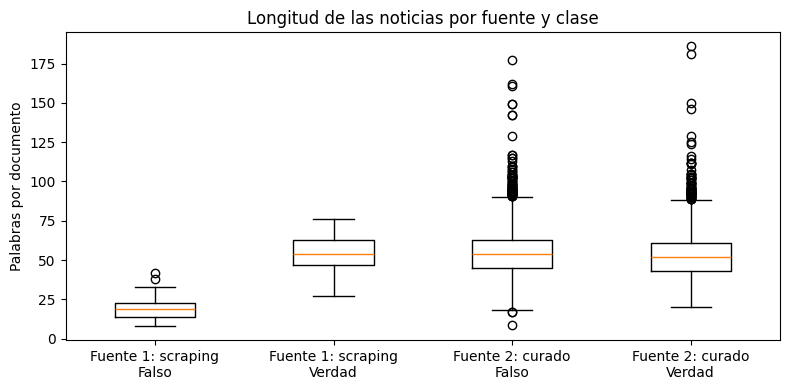

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
grupos = corpus.groupby(["origen", "clase"])["n_palabras"]
ax.boxplot([serie.values for _, serie in grupos], tick_labels=[f"{o}\n{c}" for (o, c), _ in grupos])
ax.set_ylabel("Palabras por documento")
ax.set_title("Longitud de las noticias por fuente y clase")
plt.tight_layout()
plt.savefig(DATOS / "longitud_corpus.png", dpi=150)
plt.show()

## 5. Exportar `corpus.csv`

In [20]:
corpus = corpus[["doc_id", "fuente", "origen", "clase", "label", "url", "n_palabras", "texto_crudo"]]
corpus.to_csv(DATOS / "corpus.csv", index=False, encoding="utf-8")
print(corpus.shape)
corpus.sample(5, random_state=SEMILLA)

(5150, 8)


,doc_id,fuente,origen,clase,label,url,n_palabras,texto_crudo
1176,curado_3677,curado,Fuente 2: curado,Verdad,1,,74,JxCat acaba pactando con ERC en el pueblo de Torra y deja fuera al PSC. El pleno de constitución del Ayuntamiento se tuvo que aplazar hasta las 22 horas del...
4770,curado_2196,curado,Fuente 2: curado,Falso,0,,79,El Nueva Canarias afronta en el 4M el último intento de Gabilondo por gobernar y el enésimo envite de Rita Maestre. Los socialistas arrancan la campaña cons...
1090,curado_3591,curado,Fuente 2: curado,Verdad,1,,30,"Adelante Andalucía arremete contra Más País: 'Aterriza desde Madrid y fragmenta en el espacio progresista'. El coordinador de IU, Toni Valero, afirma: No sa..."
4817,curado_2243,curado,Fuente 2: curado,Falso,0,,58,Batet confirma la fecha de la moción de censura de Tamames: será debatida y votada del 21 al 22 de marzo. Está por ver desde dónde intervendrá el candidato ...
4375,curado_1801,curado,Fuente 2: curado,Falso,0,,71,“La peor enfermedad que hay en las instituciones es el cinismo: el desapego por los problemas reales de la gente”. La candidata de Adelante Andalucía a la p...
